# 04 · Ato 3: o cliente volta?

**Projeto 1 · Tech Challenge – Fase 1 · POSTECH Data Analytics (FIAP)**
Matheus Benjamin Aquino Silva
*Trilha do projeto: o que fazer para as vendas da Olist crescerem cada vez mais?*

**Pergunta do investidor:** *o crescimento é sustentável?*

O Ato 1 (notebook 02) mostrou que a receita vem de clientes novos e estagnou em 2018. O Ato 2 (notebook 03) mostrou onde a experiência de entrega falha. Este notebook fecha o raciocínio: verifica se os clientes **voltam a comprar**, quanto vale quem volta, se a experiência da primeira compra influencia essa volta e em quais clientes vale a pena concentrar esforços de retenção.

**Perguntas que o notebook responde**

| Bloco | Perguntas | Seção |
|---|---|---|
| Recompra | P1. Quantos clientes compram mais de uma vez? · P2. Quanto tempo leva até a 2ª compra? · P3. Quantos voltam em até 6 meses? | 1 e 2 |
| Coortes | P4. A retenção melhora ao longo do tempo, de uma coorte para outra? | 3 |
| Valor | P5. Quanto vale um cliente que volta, e quanto ele pesa na receita? | 4 |
| Experiência (H6) | P6. Como os clientes avaliaram a 1ª compra? · P7. Quem teve experiência ruim volta menos? · P8. A diferença é estatisticamente significativa? | 5 |
| Categoria (H7) | P9. Algumas categorias geram mais recompra? | 6 |
| Segmentação | P10. Em quais clientes concentrar a retenção? | 7 |
| Fechamento | P11. O crescimento é sustentável, e o que falta para ser? | 8 |

**Hipóteses testadas**

| # | Hipótese |
|---|---|
| H6 | Quem tem experiência ruim na 1ª compra recompra menos |
| H7 | A recompra baixa é, em parte, estrutural da categoria (bens duráveis) |

### O que é uma coorte
**Coorte** é um grupo de pessoas que começaram algo ao mesmo tempo, como uma turma de escola: todos os alunos que entraram em 2017 formam a "turma de 2017", acompanhada ao longo dos anos para ver quantos continuam.

Neste estudo, a "turma" é formada pelos clientes que fizeram a **primeira compra no mesmo mês**. Todos os que estrearam na Olist em janeiro de 2017 são a coorte de jan/2017; os de fevereiro, a coorte de fev/2017, e assim por diante. A vantagem é comparar grupos de forma justa: em vez de misturar um cliente que chegou ontem com outro que está há um ano, cada turma é acompanhada **a partir do seu próprio começo** (1 mês depois, 2 meses depois…).

**Regras da análise**
- **Cliente = `customer_unique_id`** (decisão D5): o `customer_id` muda a cada pedido e não serve para medir recompra.
- **Só pedidos que geraram venda** (decisão D2).
- **Mesmo tempo de observação para todos:** a recompra é medida nos clientes com 1ª compra entre **jan/2017 e fev/2018**, todos com pelo menos 6 meses de acompanhamento até ago/2018, e a janela de recompra é de **até 180 dias**.
- **Compras no mesmo dia da 1ª não contam como recompra** (seção 2).

**Como ler este notebook:** cada seção abre com o objetivo, executa o código e fecha com um bloco **Leitura**, que interpreta o resultado e responde à pergunta correspondente.

## 1. Preparação dos dados e frequência de compra (P1)
O ambiente segue o padrão dos notebooks anteriores: raiz do projeto, módulos `config`, `dados` e `viz`, formatação brasileira (`br()`) e `scipy` opcional, usado só nos testes estatísticos. As bases vêm de `data/processed/`, salvas pelo notebook 01.

In [1]:
# ============================================================
# IMPORTAÇÃO DAS BIBLIOTECAS
# ============================================================

import sys
import math
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

# scipy é usado só nos testes estatísticos; se não estiver instalado, o notebook segue
try:
    from scipy import stats
    TEM_SCIPY = True
except ModuleNotFoundError:
    stats = None
    TEM_SCIPY = False
    print("Aviso: scipy não instalado. Para instalar: %pip install scipy")

# ============================================================
# LOCALIZAR RAIZ DO PROJETO
# ============================================================

RAIZ = Path.cwd().resolve()

while not (RAIZ / "src").is_dir():
    if RAIZ == RAIZ.parent:
        raise FileNotFoundError("Não foi possível localizar a pasta 'src'.")
    RAIZ = RAIZ.parent

if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

# ============================================================
# IMPORTAR MÓDULOS DO PROJETO
# ============================================================

from src import config, dados, viz

# ============================================================
# FORMATAÇÃO BRASILEIRA
# ============================================================

def br(x, casas=0):
    """Número no padrão brasileiro: 97.905 · 20,8"""
    return (
        f"{x:,.{casas}f}"
        .replace(",", "X")
        .replace(".", ",")
        .replace("X", ".")
    )

def sinal(x):
    """'+' para valores positivos (o negativo já traz o '-')."""
    return "+" if x > 0 else ""

# ============================================================
# CONFIGURAÇÕES VISUAIS
# ============================================================

viz.aplicar_estilo()

# tabelas exibidas no padrão brasileiro (2 casas decimais)
pd.set_option("display.float_format", lambda x: br(x, 2))
pd.set_option("display.max_columns", 50)

# ============================================================
# PASTA DAS BASES FINAIS (SAÍDA DO NOTEBOOK 01)
# ============================================================

PASTA_PROCESSADOS = RAIZ / "data" / "processed"

if not PASTA_PROCESSADOS.is_dir():
    raise FileNotFoundError(f"Pasta não encontrada: {PASTA_PROCESSADOS}")

print(f"Raiz do projeto:  {RAIZ}")
print(f"Bases finais:     {PASTA_PROCESSADOS.relative_to(RAIZ)}")
print(f"scipy disponível: {'sim' if TEM_SCIPY else 'não'}")

Raiz do projeto:  /home/claude/projeto-1-tech-challenge
Bases finais:     data/processed
scipy disponível: sim


In [2]:
# ============================================================
# CONTINUIDADE DO NOTEBOOK 01: CARREGAR AS BASES
# ============================================================

arquivo = PASTA_PROCESSADOS / "pedidos.pkl"
if not arquivo.exists():
    raise FileNotFoundError(f"{arquivo.relative_to(RAIZ)} não encontrado. Rode o notebook 01 primeiro.")

# PKL preserva os tipos originais, incluindo as colunas de data
pedidos = pd.read_pickle(arquivo)
gerado_em = datetime.fromtimestamp(arquivo.stat().st_mtime)
print(f"pedidos ← {arquivo.name} · gerado em {gerado_em:%d/%m/%Y %H:%M} · "
      f"{br(pedidos.shape[0])} linhas × {pedidos.shape[1]} colunas")

pedidos ← pedidos.pkl · gerado em 22/10/2026 21:22 · 99.441 linhas × 43 colunas


A base de recompra é montada em três passos:

| Passo | O que faz | Por quê |
|---|---|---|
| `vendas` | Pedidos que viraram venda e têm valor, em ordem de data | Cancelados não contam como compra (D2) |
| `n_compra` | Numera as compras de cada pessoa: 1 = primeira, 2 = segunda… | Permite separar a 1ª compra das seguintes |
| `clientes` | 1 linha por cliente, com nº de pedidos e gasto total | Unidade de análise da recompra |

Aqui **não** se aplica o filtro de janela (`na_janela`): para medir recompra interessa o histórico inteiro de cada cliente.

In [3]:
# ============================================================
# QUANTOS CLIENTES COMPRAM MAIS DE UMA VEZ? (P1)
# ============================================================

# só pedidos que viraram venda e têm valor, em ordem de data
vendas = (
    pedidos[pedidos["gerou_venda"] & pedidos["gmv"].notna()]
    .sort_values("order_purchase_timestamp")
    .copy()
)

# numera as compras de cada pessoa: 1 = primeira compra, 2 = segunda...
vendas["n_compra"] = vendas.groupby("customer_unique_id").cumcount() + 1

# 1 linha por cliente: nº de pedidos e gasto total
clientes = vendas.groupby("customer_unique_id").agg(
    pedidos=("order_id", "count"),
    gmv=("gmv", "sum"),
)

com_2 = (clientes["pedidos"] >= 2).sum()
com_3 = (clientes["pedidos"] >= 3).sum()

print(f"Clientes (pessoas distintas): {br(len(clientes))}")
print(f"Com 2+ pedidos: {br(com_2)} ({br(100 * com_2 / len(clientes), 2)}%)")
print(f"Com 3+ pedidos: {br(com_3)} ({br(100 * com_3 / len(clientes), 2)}%)")

display(clientes.head())

,pedidos,gmv
customer_unique_id,,
0000366f3b9a7992bf8c76cfdf3221e2,1,"141,90"
0000b849f77a49e4a4ce2b2a4ca5be3f,1,"27,19"
0000f46a3911fa3c0805444483337064,1,"86,22"
0000f6ccb0745a6a4b88665a16c9f078,1,"43,62"
0004aac84e0df4da2b147fca70cf8255,1,"196,89"


Clientes (pessoas distintas): 94.983
Com 2+ pedidos: 2.887 (3,04%)
Com 3+ pedidos: 236 (0,25%)


**Leitura (P1):** de cerca de 95 mil clientes, só **3%** fizeram mais de um pedido em todo o período, e menos de 0,3% fizeram três ou mais. A grande maioria compra uma única vez.

## 2. Tempo até a 2ª compra e taxa de recompra em 180 dias (P2 e P3)
Antes de calcular a taxa, verifica-se quanto tempo os clientes levam para fazer a 2ª compra. Isso revela um viés de medição importante.

In [4]:
primeira = vendas[vendas["n_compra"] == 1].set_index("customer_unique_id")
segunda = vendas[vendas["n_compra"] == 2].set_index("customer_unique_id")["order_purchase_timestamp"]
dias_ate_2a = ((segunda - primeira.loc[segunda.index, "order_purchase_timestamp"]).dt.total_seconds() / 86400)

print(f"Clientes com 2ª compra: {br(len(dias_ate_2a))}")
print(f"Dias até a 2ª compra · mediana: {br(dias_ate_2a.median())}")
print(f"2ª compra no MESMO dia da 1ª: {br(100 * (dias_ate_2a < 1).mean())}% dos casos")

Clientes com 2ª compra: 2.887
Dias até a 2ª compra · mediana: 28
2ª compra no MESMO dia da 1ª: 31% dos casos


**Leitura (P2): atenção a um viés de medição.**

| Medida | Resultado |
|---|---|
| Clientes com 2ª compra (todo o período) | 2.887 |
| Mediana de dias até a 2ª compra | 28 dias |
| 2ª compra no **mesmo dia** da 1ª | **31%** dos casos |

Quase **1 em cada 3** "recompras" acontece **no mesmo dia** da primeira compra. Na maioria dos casos é o mesmo carrinho dividido em mais de um pedido, e não um cliente que voltou. Por isso a recompra real é medida **a partir do dia seguinte** à primeira compra.

A taxa de recompra a seguir acompanha os clientes com 1ª compra entre jan/2017 e fev/2018 e conta quantos fizeram uma 2ª compra entre o dia 1 e o dia 180. A **curva acumulada** funciona como uma lista de presença: a cada dia, marca-se quem voltou pela primeira vez, e cada cliente só é contado uma vez.

Clientes na coorte (1ª compra jan/2017–fev/2018): 56.332
Recompra em até 180 dias (excluindo o mesmo dia): 1.068 clientes · 1,90%


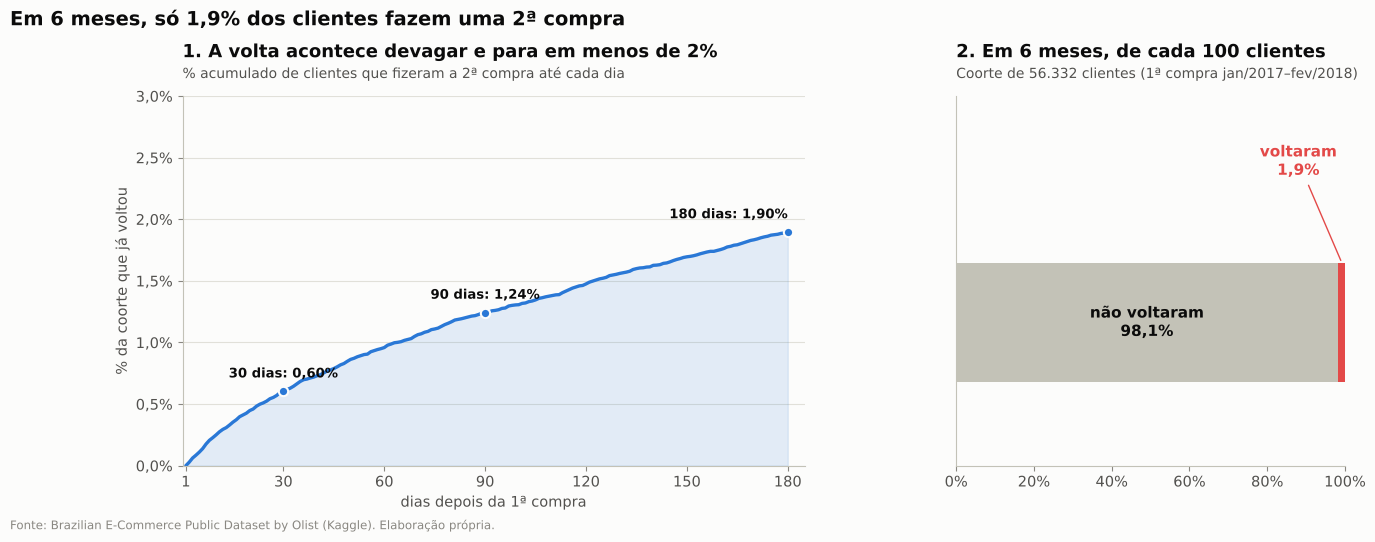

In [5]:
# ============================================================
# RECOMPRA EM ATÉ 180 DIAS (EXCLUINDO O MESMO DIA)
# ============================================================

coorte = primeira[(primeira["order_purchase_timestamp"] >= "2017-01-01") &
                  (primeira["order_purchase_timestamp"] < "2018-03-01")].copy()
coorte["dias_2a"] = dias_ate_2a.reindex(coorte.index)
coorte["recompra"] = coorte["dias_2a"].between(1, 180)
taxa_base = coorte["recompra"].mean()

n_coorte = len(coorte)
n_voltou = int(coorte["recompra"].sum())
print(f"Clientes na coorte (1ª compra jan/2017–fev/2018): {br(n_coorte)}")
print(f"Recompra em até 180 dias (excluindo o mesmo dia): {br(n_voltou)} clientes · {br(100 * taxa_base, 2)}%")

# curva acumulada: % da coorte que já fez a 2ª compra até o dia D (D = 1 a 180)
dias = np.arange(1, 181)
dias_validos = coorte["dias_2a"]
acumulado = np.array([((dias_validos >= 1) & (dias_validos <= d)).sum() for d in dias]) / n_coorte * 100
marcos = {30: acumulado[29], 90: acumulado[89], 180: acumulado[179]}

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.6, 1], "wspace": 0.3},
)

# ---------- painel 1: curva acumulada de recompra ----------
ax1.plot(dias, acumulado, color=viz.DESTAQUE, lw=2.4)
ax1.fill_between(dias, acumulado, color=viz.DESTAQUE, alpha=0.12)
for d, v in marcos.items():
    ax1.scatter([d], [v], color=viz.DESTAQUE, s=45, zorder=3, edgecolor=viz.SUPERFICIE, linewidth=1.5)
    ax1.annotate(f"{d} dias: {br(v, 2)}%", xy=(d, v), xytext=(0, 10), textcoords="offset points",
                 ha="center" if d < 180 else "right", fontsize=9.5, weight="bold", color=viz.TINTA)
ax1.set_xlim(0, 185)
ax1.set_ylim(0, 3)
ax1.set_xticks([1, 30, 60, 90, 120, 150, 180])
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{br(v, 1)}%"))
ax1.set_xlabel("dias depois da 1ª compra")
ax1.set_ylabel("% da coorte que já voltou")
viz.titulo(ax1, "1. A volta acontece devagar e para em menos de 2%",
           "% acumulado de clientes que fizeram a 2ª compra até cada dia")

# ---------- painel 2: em cada 100 clientes ----------
nao_voltou = 100 - 100 * taxa_base
ax2.barh([0], [nao_voltou], color=viz.CONTEXTO, height=0.5)
ax2.barh([0], [100 * taxa_base], left=[nao_voltou], color=viz.ALERTA, height=0.5)
ax2.text(nao_voltou / 2, 0, f"não voltaram\n{br(nao_voltou, 1)}%", ha="center", va="center",
         fontsize=11, weight="bold", color=viz.TINTA)
ax2.annotate(f"voltaram\n{br(100 * taxa_base, 1)}%", xy=(99.2, 0.25), xytext=(88, 0.62),
             fontsize=11, weight="bold", color=viz.ALERTA, ha="center",
             arrowprops=dict(arrowstyle="-", color=viz.ALERTA, lw=1))
ax2.set_xlim(0, 100)
ax2.set_ylim(-0.6, 0.95)
ax2.set_yticks([])
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(axis="y", visible=False)
viz.titulo(ax2, "2. Em 6 meses, de cada 100 clientes",
           f"Coorte de {br(n_coorte)} clientes (1ª compra jan/2017–fev/2018)")

fig.suptitle(f"Em 6 meses, só {br(100 * taxa_base, 1)}% dos clientes fazem uma 2ª compra",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.06)
viz.fonte(fig)
viz.salvar_figura(fig, "04_recompra_180_dias")
plt.show()

**Leitura (P3):**

| Prazo depois da 1ª compra | % que já voltou | Em cada 1.000 clientes |
|---|---|---|
| 30 dias | 0,60% | cerca de 6 |
| 90 dias | 1,24% | cerca de 12 |
| **180 dias** | **1,90%** (1.068 clientes) | **cerca de 19** |

- A curva só sobe, porque é acumulada, mas sobe devagar e de forma quase linear: não existe um momento em que muita gente volta de uma vez.
- Depois de 6 meses, **98 de cada 100 clientes não voltaram**.

**Conclusão:** este é o achado mais importante do estudo. A Olist praticamente não tem base recorrente: cada mês de receita depende de conquistar clientes novos.

## 3. Análise de coorte: retenção mês a mês (P4)
Cada linha do mapa de calor é uma **coorte** (clientes com a 1ª compra no mesmo mês) e cada coluna conta os meses depois dessa 1ª compra (mês 1 = mês seguinte). O valor de cada quadrado é o % da coorte que comprou de novo **naquele mês**.

*Por que só até fev/2018:* a base termina em ago/2018, e uma coorte posterior não teria os 6 meses completos de acompanhamento.

,mês 1,mês 2,mês 3,mês 4,mês 5,mês 6,clientes na coorte
jan/17,"0,40","0,27","0,13","0,40","0,13","0,40",752
fev/17,"0,24","0,30","0,12","0,41","0,12","0,24",1690
mar/17,"0,51","0,35","0,39","0,35","0,16","0,16",2571
abr/17,"0,60","0,22","0,17","0,30","0,26","0,34",2325
mai/17,"0,48","0,48","0,40","0,31","0,34","0,42",3541
jun/17,"0,45","0,35","0,39","0,26","0,39","0,35",3102
jul/17,"0,52","0,34","0,24","0,29","0,21","0,31",3822
ago/17,"0,68","0,34","0,27","0,36","0,53","0,29",4130
set/17,"0,69","0,54","0,29","0,44","0,22","0,22",4075
out/17,"0,71","0,25","0,09","0,23","0,20","0,20",4392


Retenção média nos meses 1 a 6: 0,31% ao mês · máxima: 0,71%


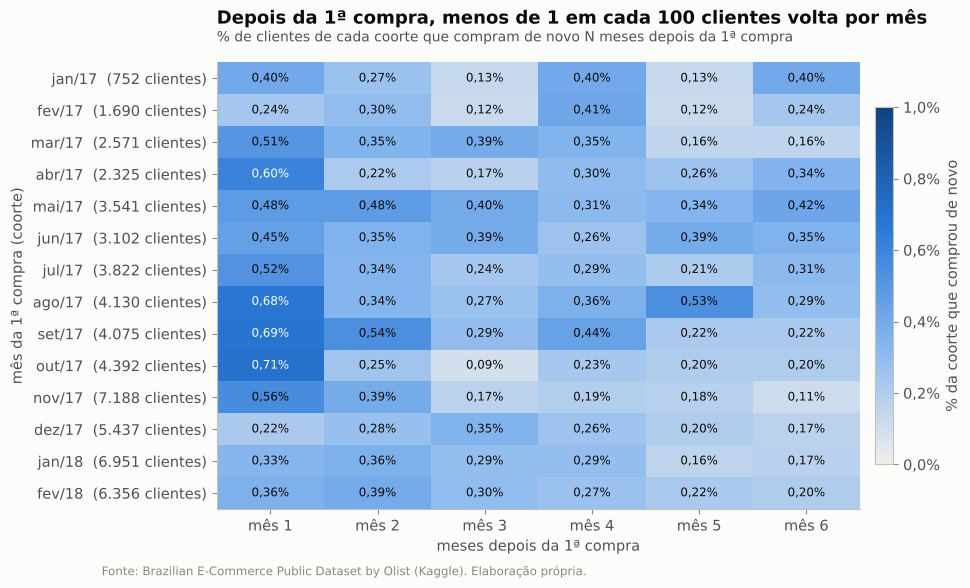

In [6]:
# ============================================================
# RETENÇÃO POR COORTE: QUANTOS VOLTAM N MESES DEPOIS?
# ============================================================

# coorte = mês da 1ª compra de cada cliente
vendas["coorte"] = vendas.groupby("customer_unique_id")["order_purchase_timestamp"].transform("min").dt.to_period("M")
# período = mês de cada compra
vendas["periodo"] = vendas["order_purchase_timestamp"].dt.to_period("M")
# mês relativo = quantos meses depois da 1ª compra aconteceu esta compra (0 = mês da 1ª compra)
vendas["mes_relativo"] = (vendas["periodo"] - vendas["coorte"]).apply(lambda x: x.n)

# coortes de jan/2017 a fev/2018: todas têm pelo menos 6 meses de acompanhamento até ago/2018
base = vendas[(vendas["coorte"] >= "2017-01") & (vendas["coorte"] <= "2018-02")]
ret = base.groupby(["coorte", "mes_relativo"])["customer_unique_id"].nunique().unstack(fill_value=0)

tamanho_coorte = ret[0]                                   # clientes que fizeram a 1ª compra no mês
retencao = ret.div(tamanho_coorte, axis=0).iloc[:, 1:7] * 100
rotulos = [f"{viz.MESES[p.month - 1]}/{p.year % 100:02d}" for p in retencao.index]
retencao.index = rotulos
retencao.columns = [f"mês {k}" for k in retencao.columns]

print(f"Retenção média nos meses 1 a 6: {br(retencao.values.mean(), 2)}% ao mês · "
      f"máxima: {br(retencao.values.max(), 2)}%")
display(retencao.assign(**{"clientes na coorte": tamanho_coorte.values}).round(2))

# ------------------------------------------------------------
# PALETA DO HEATMAP: troque pelos códigos de cor dos seus dashboards
# (do valor mais baixo para o mais alto)
# ------------------------------------------------------------
PALETA_HEATMAP = ["#f0efec", "#86b6ef", "#2a78d6", "#104281"]
cmap = LinearSegmentedColormap.from_list("paleta_heatmap", PALETA_HEATMAP)

fig, ax = plt.subplots(figsize=(10, 5.8))
vmax = 1.0
im = ax.imshow(retencao.values, cmap=cmap, vmin=0, vmax=vmax, aspect="auto")
for i in range(retencao.shape[0]):
    for j in range(retencao.shape[1]):
        v = retencao.values[i, j]
        ax.text(j, i, f"{br(v, 2)}%", ha="center", va="center", fontsize=8.5,
                color="white" if v > 0.6 * vmax else viz.TINTA)

ax.set_xticks(range(retencao.shape[1]), retencao.columns)
ax.set_yticks(range(len(rotulos)), [f"{r}  ({br(n)} clientes)" for r, n in zip(rotulos, tamanho_coorte)])
ax.set_xlabel("meses depois da 1ª compra")
ax.set_ylabel("mês da 1ª compra (coorte)")
ax.grid(False)
barra = fig.colorbar(im, ax=ax, shrink=0.8, pad=0.02)
barra.ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{br(v, 1)}%"))
barra.set_label("% da coorte que comprou de novo")
viz.titulo(ax, "Depois da 1ª compra, menos de 1 em cada 100 clientes volta por mês",
           "% de clientes de cada coorte que compram de novo N meses depois da 1ª compra")
viz.fonte(fig)
viz.salvar_figura(fig, "04_coortes")
plt.show()

**Leitura (P4):**

| Medida | Resultado |
|---|---|
| Retenção média, meses 1 a 6 | **0,31% ao mês** |
| Maior valor encontrado | 0,71% (coorte de out/2017, no mês seguinte) |
| Coortes acompanhadas | jan/2017 a fev/2018 (todas com 6 meses completos de acompanhamento) |

- **Em nenhuma coorte e em nenhum mês a recompra chega a 1%.**
- **Não há melhora com o tempo:** as coortes de 2018 retêm tão pouco quanto as de 2017; a operação não aprendeu a trazer o cliente de volta.

**Conclusão:** a Olist praticamente não forma uma base de clientes recorrentes. Cada mês de receita depende de conquistar clientes novos, o que explica o platô de 2018 visto no notebook 02.

## 4. Valor do cliente recorrente (P5)
Compara-se a receita média por cliente (vendas acumuladas no período) entre quem comprou uma única vez e quem comprou duas ou mais vezes, e o peso de cada grupo no total de clientes e de receita.

,clientes,Vendas médias por cliente (R$),% das vendas totais,% dos clientes
compra única,92096,"161,20","94,30","97,00"
recorrente (2+ pedidos),2887,"308,40","5,70","3,00"


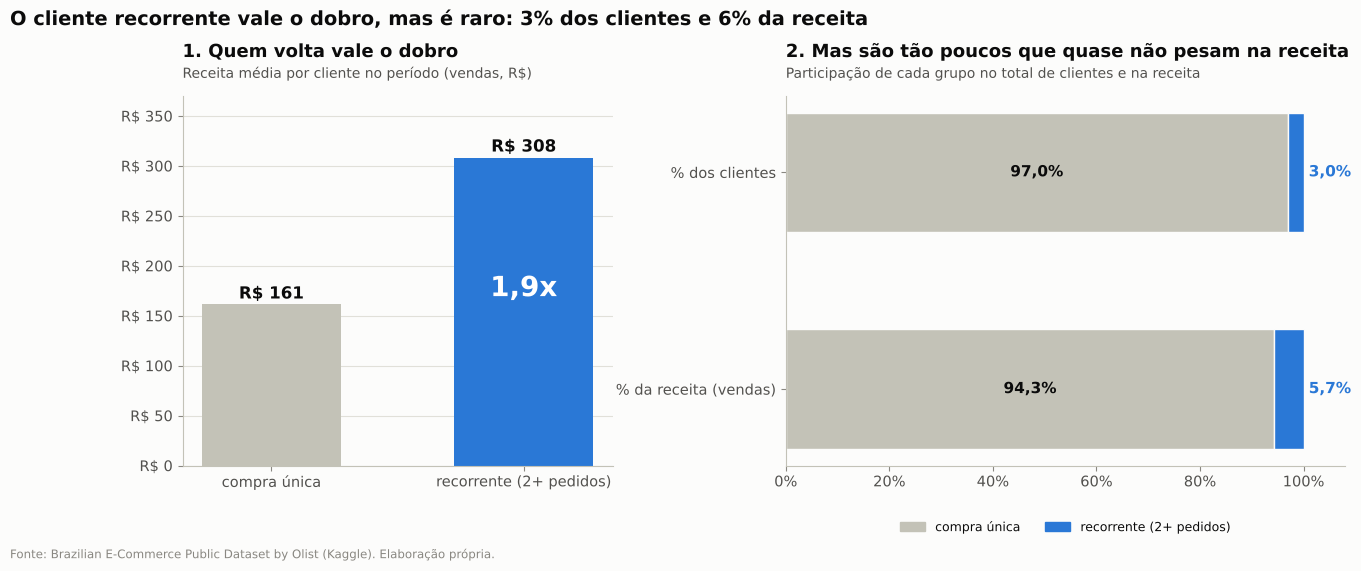

In [7]:
# ============================================================
# QUANTO VALE UM CLIENTE QUE VOLTA?
# ============================================================

recorrentes = clientes["pedidos"] >= 2
valor = pd.DataFrame({
    "clientes": [(~recorrentes).sum(), recorrentes.sum()],
    "Vendas médias por cliente (R$)": [clientes.loc[~recorrentes, "gmv"].mean(), clientes.loc[recorrentes, "gmv"].mean()],
    "% das vendas totais": [100 * clientes.loc[~recorrentes, "gmv"].sum() / clientes["gmv"].sum(),
                       100 * clientes.loc[recorrentes, "gmv"].sum() / clientes["gmv"].sum()],
}, index=["compra única", "recorrente (2+ pedidos)"])
valor["% dos clientes"] = 100 * valor["clientes"] / valor["clientes"].sum()
display(valor.round(1))

grupos = ["compra única", "recorrente (2+ pedidos)"]
cores = {"compra única": viz.CONTEXTO, "recorrente (2+ pedidos)": viz.DESTAQUE}
multiplo = valor.loc[grupos[1], "Vendas médias por cliente (R$)"] / valor.loc[grupos[0], "Vendas médias por cliente (R$)"]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3], "wspace": 0.35},
)

# ---------- painel 1: valor de cada cliente ----------
barras = ax1.bar(grupos, valor["Vendas médias por cliente (R$)"], color=[cores[g] for g in grupos], width=0.55)
for b, v in zip(barras, valor["Vendas médias por cliente (R$)"]):
    ax1.text(b.get_x() + b.get_width() / 2, v + 6, f"R\\$ {br(v)}", ha="center",
             fontsize=12, weight="bold", color=viz.TINTA)
ax1.annotate(f"{br(multiplo, 1)}x", xy=(1, valor.iloc[1, 1] * 0.55), ha="center",
             fontsize=20, weight="bold", color="white")
ax1.set_ylim(0, valor["Vendas médias por cliente (R$)"].max() * 1.2)
ax1.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"R$ {br(v)}"))
ax1.grid(axis="x", visible=False)
viz.titulo(ax1, "1. Quem volta vale o dobro",
           "Receita média por cliente no período (vendas, R$)")

# ---------- painel 2: peso de cada grupo nos clientes e na receita ----------
medidas = {"% dos clientes": valor["% dos clientes"], "% da receita (vendas)": valor["% das vendas totais"]}
for y, (nome, serie) in enumerate(medidas.items()):
    esquerda = 0
    for g in grupos:
        v = serie[g]
        ax2.barh(y, v, left=esquerda, color=cores[g], height=0.55,
                 edgecolor=viz.SUPERFICIE, linewidth=1)
        if v >= 10:
            ax2.text(esquerda + v / 2, y, f"{br(v, 1)}%", ha="center", va="center", fontsize=11,
                     weight="bold", color="white" if g == grupos[1] else viz.TINTA)
        else:
            ax2.text(101, y, f"{br(v, 1)}%", ha="left", va="center", fontsize=11,
                     weight="bold", color=viz.DESTAQUE)
        esquerda += v
ax2.set_yticks(range(len(medidas)), list(medidas))
ax2.invert_yaxis()
ax2.set_xlim(0, 108)
ax2.set_xticks(range(0, 101, 20))
ax2.xaxis.set_major_formatter(mtick.PercentFormatter(decimals=0))
ax2.grid(axis="y", visible=False)
ax2.legend(handles=[Patch(color=cores[g], label=g) for g in grupos],
           loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2, fontsize=9)
viz.titulo(ax2, "2. Mas são tão poucos que quase não pesam na receita",
           "Participação de cada grupo no total de clientes e na receita")

fig.suptitle("O cliente recorrente vale o dobro, mas é raro: 3% dos clientes e 6% da receita",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.06)
viz.fonte(fig)
viz.salvar_figura(fig, "04_valor_recorrente")
plt.show()

**Leitura (P5):**

| Grupo | Clientes | % dos clientes | Receita média por cliente | % da receita |
|---|---|---|---|---|
| Compra única | 92.096 | 97,0% | R$ 161 | 94,3% |
| Recorrente (2+ pedidos) | 2.887 | **3,0%** | **R$ 308** | **5,7%** |

- **Quem volta vale o dobro:** o cliente recorrente gera, em média, 1,9 vez a receita de quem compra uma vez só.
- **Mas é raro:** os recorrentes são só 3% dos clientes e somam menos de 6% da receita.

**Implicação para o investidor:** cada ponto percentual de recompra conquistado é receita que **não depende** de novo investimento em aquisição.

## 5. Experiência da 1ª compra e recompra (P6, P7 e P8 · H6)
A pergunta é se a experiência da primeira compra, medida pela nota que o cliente deu (1 a 5) e pelo atraso na entrega, influencia a chance de ele voltar. A tabela mostra, para cada nota, quantos clientes a deram, quantos voltaram em até 180 dias e a taxa de recompra.

In [8]:
def taxa_por_grupo(df, grupo):
    t = df.groupby(grupo)["recompra"].agg(clientes="count", recompras="sum", taxa="mean")
    t["taxa"] *= 100
    return t

por_nota = taxa_por_grupo(coorte.dropna(subset=["review_score"]), "review_score")
por_nota.index = por_nota.index.astype(int).rename("nota da 1ª compra")
por_nota["% dos clientes"] = 100 * por_nota["clientes"] / por_nota["clientes"].sum()
display(por_nota.round(2))

boas = por_nota.loc[[4, 5], "clientes"].sum() / por_nota["clientes"].sum()
ruins = por_nota.loc[[1, 2], "clientes"].sum() / por_nota["clientes"].sum()
print(f"Notas 4 e 5: {br(100 * boas)}% dos clientes · notas 1 e 2: {br(100 * ruins)}%")

,clientes,recompras,taxa,% dos clientes
nota da 1ª compra,,,,
1,6167,97,"1,57","11,04"
2,1835,27,"1,47","3,28"
3,4866,89,"1,83","8,71"
4,11089,192,"1,73","19,85"
5,31917,658,"2,06","57,12"


Notas 4 e 5: 77% dos clientes · notas 1 e 2: 14%


**Leitura (P6):**

| Nota da 1ª compra | % dos clientes | Taxa de recompra |
|---|---|---|
| 1 e 2 (ruins) | 14% | cerca de 1,5% |
| 3 (neutra) | 9% | 1,8% |
| 4 e 5 (boas) | **77%** | 1,7% a **2,1%** |

- **3 em cada 4 clientes saíram satisfeitos** da primeira compra (nota 4 ou 5).
- A taxa de recompra fica **perto de 2% em todas as notas**: tanto quem detestou quanto quem adorou a primeira compra volta pouco.
- A maior parte de quem volta vem do grupo da nota 5 simplesmente porque esse grupo é o maior.

O próximo passo testa se a pequena diferença entre notas ruins e boas é real ou fruto do acaso.

### 5.1 Teste de diferença entre proporções (P8)
O **teste z para duas proporções** compara a taxa de recompra de dois grupos (avaliação boa × ruim; entregue no prazo × atrasado). A hipótese nula é que as taxas são iguais; um p-valor abaixo de 0,05 indica que a diferença dificilmente é obra do acaso. Se o `scipy` não estiver instalado, o p-valor é calculado com a função de erro complementar (`math.erfc`), que dá o mesmo resultado da distribuição normal.

In [9]:
def teste_proporcoes(a, b):
    """Teste z de diferença entre duas proporções (bicaudal)."""
    p1, n1, p2, n2 = a.mean(), len(a), b.mean(), len(b)
    p = (a.sum() + b.sum()) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    if TEM_SCIPY:
        p_valor = 2 * stats.norm.sf(abs(z))
    else:
        p_valor = math.erfc(abs(z) / math.sqrt(2))   # mesmo resultado, sem scipy
    return p1, p2, p_valor

aval = coorte.dropna(subset=["review_score"])
ruim = aval["avaliacao_ruim"].astype(bool)
p_boa, p_ruim, pv1 = teste_proporcoes(aval.loc[~ruim, "recompra"], aval.loc[ruim, "recompra"])

ent = coorte[coorte["entregue"]]
atr = ent["atrasado"].astype(bool)
p_prazo, p_atr, pv2 = teste_proporcoes(ent.loc[~atr, "recompra"], ent.loc[atr, "recompra"])

teste = pd.DataFrame({
    "taxa · grupo de referência (%)": [100 * p_boa, 100 * p_prazo],
    "taxa · grupo afetado (%)": [100 * p_ruim, 100 * p_atr],
    "queda relativa (%)": [100 * (1 - p_ruim / p_boa), 100 * (1 - p_atr / p_prazo)],
    "p-valor": [pv1, pv2],
}, index=["avaliação boa (3–5) × ruim (1–2)", "entregue no prazo × atrasado"])
teste["p-valor"] = teste["p-valor"].map(lambda v: br(v, 3))   # 3 casas: p-valores pequenos
display(teste.round(2))

,taxa · grupo de referência (%),taxa · grupo afetado (%),queda relativa (%),p-valor
avaliação boa (3–5) × ruim (1–2),"1,96","1,55","21,00","0,013"
entregue no prazo × atrasado,"1,93","1,47","23,87","0,048"


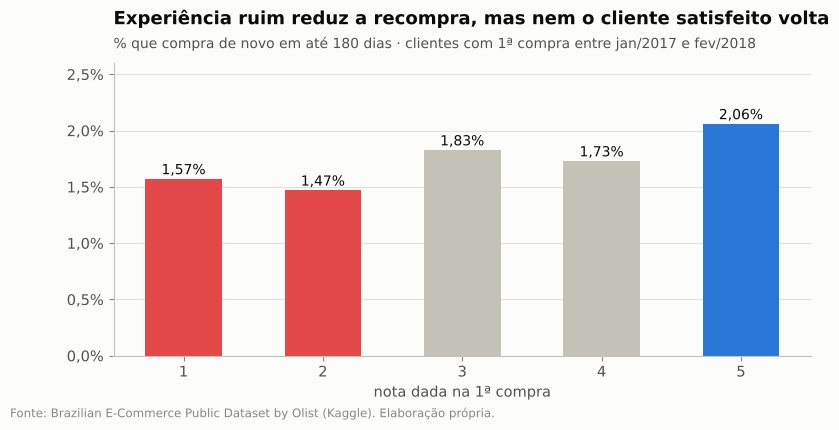

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.bar(por_nota.index.astype(str), por_nota["taxa"], width=0.55,
       color=[viz.ALERTA, viz.ALERTA, viz.CONTEXTO, viz.CONTEXTO, viz.DESTAQUE])
for i, v in enumerate(por_nota["taxa"]):
    ax.text(i, v + 0.04, f"{br(v, 2)}%", ha="center", fontsize=10)
ax.yaxis.set_major_formatter(viz.formato_pct(1))
ax.set_ylim(0, 2.6)
ax.set_xlabel("nota dada na 1ª compra")
viz.titulo(ax, "Experiência ruim reduz a recompra, mas nem o cliente satisfeito volta",
           "% que compra de novo em até 180 dias · clientes com 1ª compra entre jan/2017 e fev/2018")
viz.fonte(fig)
viz.salvar_figura(fig, "04_recompra_nota")
plt.show()

**Leitura (P7 e P8): H6 confirmada, com uma ressalva importante.**

| Comparação | Grupo de referência | Grupo afetado | Queda relativa | p-valor |
|---|---|---|---|---|
| Avaliação boa (3–5) × ruim (1–2) | 1,96% | 1,55% | **−21%** | 0,013 |
| Entregue no prazo × atrasado | 1,93% | 1,47% | **−24%** | 0,048 |

- Quem teve experiência ruim volta **cerca de 20 a 25% menos**, e as duas diferenças são estatisticamente significativas a 5%.
- **A ressalva:** a diferença é pequena em termos absolutos (cerca de 0,4 ponto percentual). Mesmo o cliente que deu **nota 5** só volta em **2,1%** dos casos.

**Conclusão:** a experiência ruim **piora** a recompra, mas **não explica** por que ela é tão baixa. O cliente sai satisfeito e mesmo assim não volta: a Olist resolve a compra, mas não constrói relacionamento. Corrigir a logística é necessário, porque protege a reputação e reduz a perda de clientes, mas **não basta**; falta um **mecanismo de retenção** que convide o cliente a voltar.

## 6. Recompra por categoria (P9 · H7)
Compara-se a taxa de recompra em até 180 dias conforme a categoria do produto da 1ª compra, considerando só categorias com pelo menos 500 clientes, para que as taxas sejam estáveis. Em azul, as categorias com recompra pelo menos 25% acima da média.

,clientes,taxa
categoria_principal,,
pet shop,828,"2,90"
fashion bolsas e acessorios,1157,"2,85"
esporte lazer,4569,"2,58"
cama mesa banho,5440,"2,46"
moveis decoracao,3759,"2,34"
ferramentas jardim,2332,"2,02"
perfumaria,1989,"2,01"
bebes,1512,"1,92"
beleza saude,4387,"1,89"


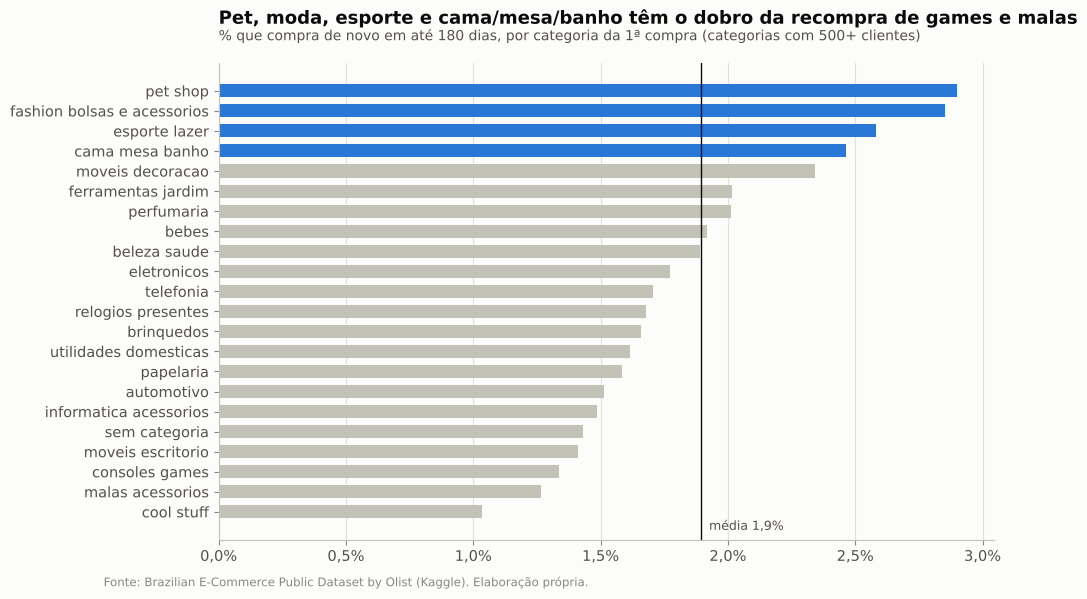

In [11]:
cat = coorte.groupby("categoria_principal")["recompra"].agg(clientes="count", taxa="mean")
cat = cat[cat["clientes"] >= 500].sort_values("taxa")
cat["taxa"] *= 100

fig, ax = plt.subplots(figsize=(10, 6.2))
media = 100 * taxa_base
ax.barh(cat.index, cat["taxa"], height=0.65,
        color=[viz.DESTAQUE if v >= 1.25 * media else viz.CONTEXTO for v in cat["taxa"]])
ax.axvline(media, color=viz.TINTA, lw=1)
ax.text(media + 0.03, -0.9, f"média {br(media, 1)}%", fontsize=9, color=viz.TINTA_SECUNDARIA)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(viz.formato_pct(1))
viz.titulo(ax, "Pet, moda, esporte e cama/mesa/banho têm o dobro da recompra de games e malas",
           "% que compra de novo em até 180 dias, por categoria da 1ª compra (categorias com 500+ clientes)")
viz.fonte(fig)
viz.salvar_figura(fig, "04_recompra_categoria")
plt.show()
display(cat.sort_values("taxa", ascending=False).round(2))

**Leitura (P9): H7 confirmada.**

| Tipo de categoria | Exemplos | Recompra em 180 dias |
|---|---|---|
| **Reposição e consumo frequente** | pet shop, bolsas e acessórios, esporte e lazer, cama mesa e banho, móveis e decoração | **2,3% a 2,9%** |
| Compra pontual (bens duráveis) | cool stuff, malas, consoles, móveis de escritório | 1,0% a 1,4% |

- Parte da recompra baixa é **estrutural**: quem compra um console ou uma mala não precisa de outro tão cedo.
- Mesmo nas melhores categorias, porém, a recompra não chega a 3%.

**Implicação:** um programa de retenção deve começar pelas categorias com recompra natural, onde o retorno por real investido tende a ser maior.

## 7. Segmentação RFM (P10)
O **RFM** separa os clientes por três critérios: **R**ecência (há quanto tempo comprou pela última vez), **F**requência (quantas vezes comprou) e **M**onetário (quanto gastou). Na Olist, a frequência quase não diferencia ninguém, porque 97% dos clientes compraram uma única vez, e isso já é um achado em si.

Por isso a segmentação usa duas réguas, **recência × valor**, e separa à parte os poucos clientes recorrentes:

| Régua | Critério |
|---|---|
| **Valor** | Alto valor = entre os 20% que mais gastaram no período (corte calculado nos dados) |
| **Recência** | Recente = última compra até 180 dias antes da data de referência (01/09/2018, dia seguinte ao fim da base) |
| **Recorrentes** | Clientes com 2 ou mais pedidos, que ficam fora da matriz porque já voltaram |

As duas réguas formam uma matriz de 4 segmentos, e cada um recebe uma ação de retenção diferente.

,clientes,% clientes,% vendas,ticket,recencia_mediana,ação sugerida
segmento,,,,,,
1. Recorrentes,2874,"3,03","5,65","308,36","202,00",Fidelizar: benefícios e acesso antecipado
"2. Alto valor, recente",7103,"7,50","20,43","451,19","97,00",Prioridade: convite para a 2ª compra em até 60 dias
"3. Alto valor, distante",10266,"10,84","28,63","437,39","319,00",Reativar com oferta de categoria relacionada
"4. Baixo valor, recente",29967,"31,64","18,50","96,83","96,00","Cross-sell de baixo custo (e-mail, cupom de frete)"
"5. Baixo valor, distante",44493,"46,98","26,78","94,41","314,00",Baixa prioridade; campanhas sazonais (Black Friday)


frequencia
1   97,00
2    2,80
3    0,20

Corte de alto valor (20% maiores): R$ 208,97


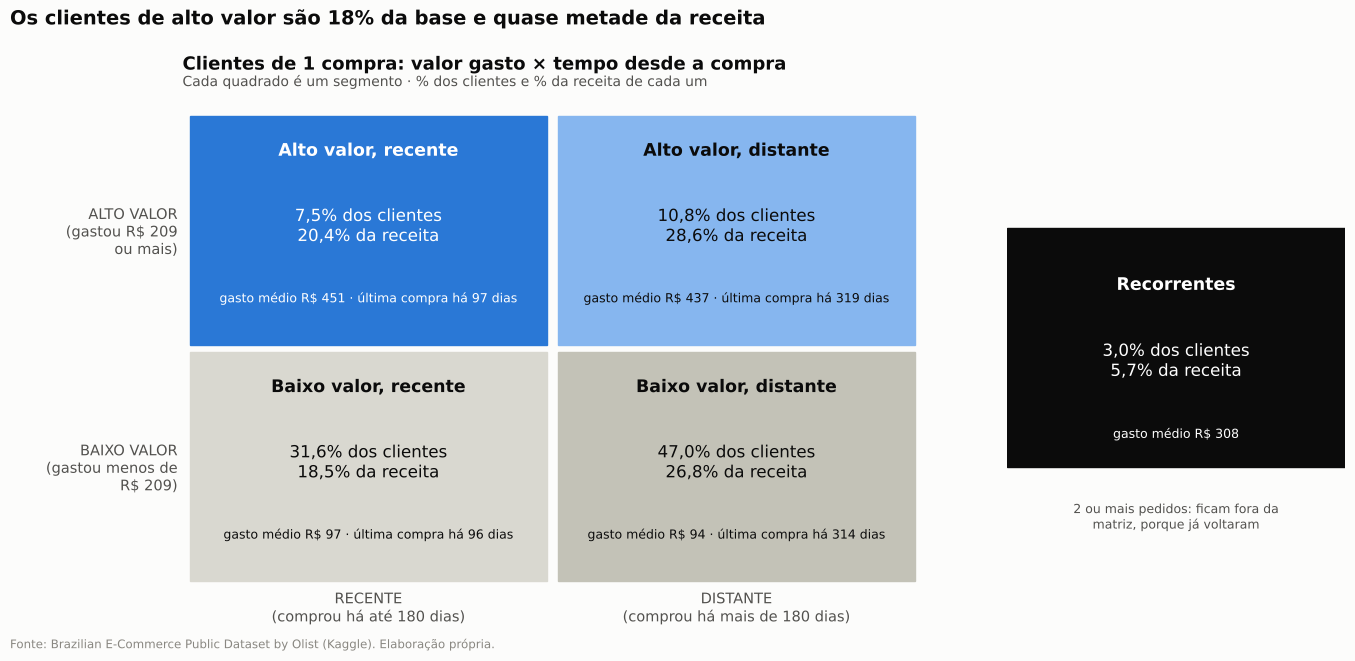

In [12]:
# ============================================================
# SEGMENTAÇÃO RFM (RECÊNCIA × VALOR)
# ============================================================

ref = pd.Timestamp("2018-09-01")          # data de referência: dia seguinte ao fim da base
jan = vendas[vendas["na_janela"]]
rfm = jan.groupby("customer_unique_id").agg(
    recencia_dias=("order_purchase_timestamp", lambda s: (ref - s.max()).days),
    frequencia=("order_id", "count"),
    monetario=("gmv", "sum"))
print(rfm["frequencia"].value_counts(normalize=True).head(3).mul(100).round(1).rename("% clientes").to_string())

corte_m = rfm["monetario"].quantile(0.8)   # alto valor = 20% que mais gastaram
def segmento(r):
    if r["frequencia"] >= 2:
        return "1. Recorrentes"
    alto = r["monetario"] >= corte_m
    recente = r["recencia_dias"] <= 180
    return {(True, True): "2. Alto valor, recente", (True, False): "3. Alto valor, distante",
            (False, True): "4. Baixo valor, recente", (False, False): "5. Baixo valor, distante"}[(alto, recente)]
rfm["segmento"] = rfm.apply(segmento, axis=1)
seg = rfm.groupby("segmento").agg(clientes=("monetario", "size"), gmv=("monetario", "sum"),
                                  ticket=("monetario", "mean"), recencia_mediana=("recencia_dias", "median"))
seg["% clientes"] = 100 * seg["clientes"] / seg["clientes"].sum()
seg["% vendas"] = 100 * seg["gmv"] / seg["gmv"].sum()
acoes = {
    "1. Recorrentes": "Fidelizar: benefícios e acesso antecipado",
    "2. Alto valor, recente": "Prioridade: convite para a 2ª compra em até 60 dias",
    "3. Alto valor, distante": "Reativar com oferta de categoria relacionada",
    "4. Baixo valor, recente": "Cross-sell de baixo custo (e-mail, cupom de frete)",
    "5. Baixo valor, distante": "Baixa prioridade; campanhas sazonais (Black Friday)",
}
seg["ação sugerida"] = seg.index.map(acoes)
print(f"\nCorte de alto valor (20% maiores): R$ {br(corte_m, 2)}")
display(seg[["clientes", "% clientes", "% vendas", "ticket", "recencia_mediana", "ação sugerida"]])

# ------------------------------------------------------------
# GRÁFICO: matriz 2 × 2 (recência × valor) + recorrentes à parte
# ------------------------------------------------------------
quadrantes = {
    # segmento: (coluna, linha, cor)  · coluna 0 = recente, 1 = distante · linha 0 = alto, 1 = baixo
    "2. Alto valor, recente": (0, 0, viz.DESTAQUE),
    "3. Alto valor, distante": (1, 0, "#86b6ef"),
    "4. Baixo valor, recente": (0, 1, "#d9d8d0"),
    "5. Baixo valor, distante": (1, 1, viz.CONTEXTO),
}
fig, (ax, ax_r) = plt.subplots(1, 2, figsize=(15, 6.2), gridspec_kw={"width_ratios": [2.2, 1], "wspace": 0.15})

for nome, (col, lin, cor) in quadrantes.items():
    r = seg.loc[nome]
    ax.add_patch(plt.Rectangle((col, 1 - lin), 0.97, 0.97, color=cor))
    texto_cor = "white" if cor == viz.DESTAQUE else viz.TINTA
    ax.text(col + 0.485, 1 - lin + 0.80, nome[3:], ha="center", fontsize=12.5, weight="bold", color=texto_cor)
    ax.text(col + 0.485, 1 - lin + 0.50,
            f"{br(r['% clientes'], 1)}% dos clientes\n{br(r['% vendas'], 1)}% da receita",
            ha="center", va="center", fontsize=12, color=texto_cor)
    ax.text(col + 0.485, 1 - lin + 0.18,
            f"gasto médio R\\$ {br(r['ticket'])} · última compra há {br(r['recencia_mediana'])} dias",
            ha="center", fontsize=9, color=texto_cor)
ax.set_xlim(-0.02, 2)
ax.set_ylim(-0.02, 2)
ax.set_xticks([0.485, 1.485], ["RECENTE\n(comprou há até 180 dias)", "DISTANTE\n(comprou há mais de 180 dias)"])
ax.set_yticks([0.485, 1.485], [f"BAIXO VALOR\n(gastou menos de\nR$ {br(corte_m)})", f"ALTO VALOR\n(gastou R$ {br(corte_m)}\nou mais)"])
ax.tick_params(length=0)
for lado in ax.spines.values():
    lado.set_visible(False)
ax.grid(False)
viz.titulo(ax, "Clientes de 1 compra: valor gasto × tempo desde a compra",
           "Cada quadrado é um segmento · % dos clientes e % da receita de cada um")

# recorrentes à parte
r = seg.loc["1. Recorrentes"]
ax_r.add_patch(plt.Rectangle((0, 0.25), 1, 0.5, color=viz.TINTA))
ax_r.text(0.5, 0.62, "Recorrentes", ha="center", fontsize=12.5, weight="bold", color="white")
ax_r.text(0.5, 0.47, f"{br(r['% clientes'], 1)}% dos clientes\n{br(r['% vendas'], 1)}% da receita",
          ha="center", va="center", fontsize=12, color="white")
ax_r.text(0.5, 0.31, f"gasto médio R\\$ {br(r['ticket'])}", ha="center", fontsize=9, color="white")
ax_r.text(0.5, 0.12, "2 ou mais pedidos: ficam fora da\nmatriz, porque já voltaram", ha="center",
          fontsize=9, color=viz.TINTA_SECUNDARIA)
ax_r.set_xlim(0, 1)
ax_r.set_ylim(0, 1)
ax_r.axis("off")

fig.suptitle("Os clientes de alto valor são 18% da base e quase metade da receita",
             x=0.01, ha="left", fontsize=14, fontweight="bold", y=1.04)
viz.fonte(fig)
viz.salvar_figura(fig, "04_rfm_matriz")
plt.show()

**Leitura (P10):**

| Segmento | % dos clientes | % da receita | Gasto médio | Ação sugerida |
|---|---|---|---|---|
| **Alto valor, recente** | 7,5% | 20,4% | R$ 451 | **Prioridade:** convite para a 2ª compra em até 60 dias |
| Alto valor, distante | 10,8% | 28,6% | R$ 437 | Reativar com oferta de categoria relacionada |
| Baixo valor, recente | 31,6% | 18,5% | R$ 97 | Cross-sell de baixo custo (e-mail, cupom de frete) |
| Baixo valor, distante | 47,0% | 26,8% | R$ 94 | Baixa prioridade; campanhas sazonais |
| Recorrentes | 3,0% | 5,7% | R$ 308 | Fidelizar: benefícios e acesso antecipado |

- Os dois segmentos de **alto valor** somam **18% dos clientes e quase metade da receita (49%)**.
- **Alto valor, recente** é o alvo mais óbvio para uma campanha de segunda compra: gastou muito, comprou há menos de 6 meses e ainda lembra da marca.

**Conclusão:** com recompra de 2%, qualquer melhora nesse grupo tem efeito visível na receita.

## 8. Conclusão do Ato 3 (P11)

**Resposta curta:** o cliente sai satisfeito, mas não volta. O crescimento da Olist não é sustentável enquanto depender só de conquistar clientes novos.

| Pergunta | Resposta |
|---|---|
| O cliente volta? (P1–P3) | **Quase nunca.** 3% fizeram mais de um pedido; só **1,9%** voltam em até 6 meses (excluindo o mesmo dia) |
| A retenção melhora com o tempo? (P4) | **Não.** Em nenhuma coorte e em nenhum mês a recompra chega a 1%; as coortes de 2018 retêm tão pouco quanto as de 2017 |
| Quanto vale quem volta? (P5) | **O dobro:** R$ 308 contra R$ 161 por cliente, mas os recorrentes somam só 5,7% da receita |
| A experiência ruim afasta? (P6–P8) | **Sim, mas pouco:** −21% (nota ruim) e −24% (atraso), com significância estatística. Mesmo o cliente nota 5 só volta em 2,1% dos casos |
| A categoria importa? (P9) | **Sim:** produtos de reposição (pet, moda, esporte, casa) têm o dobro da recompra de bens duráveis |
| Por onde começar? (P10) | Clientes de **alto valor e recentes** (7,5% dos clientes, 20% da receita) e categorias de reposição |

| Hipótese | Resultado |
|---|---|
| H6: experiência ruim reduz recompra | ✅ **Confirmada** (−21% a −24%, p < 0,05), com efeito absoluto pequeno |
| H7: recompra depende da categoria | ✅ **Confirmada** (de 1,0% a 2,9%) |

**Resposta à P11:** a logística (Ato 2) explica parte da insatisfação, mas não a falta de recompra. O problema principal é a **ausência de um mecanismo de retenção**: nada na jornada convida o cliente a voltar, nem o que saiu satisfeito. Para o crescimento se tornar sustentável, a Olist precisa atuar em duas frentes: **qualidade da entrega** (reduz a perda) e **retenção ativa** (campanha de 2ª compra, cupom, fidelidade), começando pelos clientes de alto valor e pelas categorias de reposição.

**Próximo passo:** `05_modelo_e_recomendacoes.ipynb`: o que fazer, quanto vale cada alavanca e como antecipar o cliente insatisfeito.